# Section 2 · Task 2.3 — Visualize Quantum States

**Exam:** C1000-179 *Fundamentals of Quantum Computing Using Qiskit v2.X Developer*
**Section 2:** Visualize quantum circuits, measurements, and states (≈ 11 % of the exam) → **Task 2.3: Visualize quantum states**
**Official references from the study guide:**
- [`plot_bloch_multivector`](https://quantum.cloud.ibm.com/docs/en/api/qiskit/qiskit.visualization.plot_bloch_multivector)
- [`plot_state_qsphere`](https://quantum.cloud.ibm.com/docs/en/api/qiskit/qiskit.visualization.plot_state_qsphere)

Extended reading: [Plot quantum states (guide)](https://quantum.cloud.ibm.com/docs/en/guides/plot-quantum-states)

---

### IBM's self-test applied here
1. **How** do you plot a state: which functions, which inputs, which options?
2. **Why** do the pictures look the way they do — what *exactly* does each Bloch sphere in a multi-qubit plot show, and how do you read a Q-sphere?
3. **What goes wrong if you misread them?** (an entangled qubit shows a *zero-length* arrow; the Q-sphere hides global phase; Bloch spheres cannot tell two entangled states apart …)

### What you will be able to do afterwards
- Compute the **Bloch vector** $(\langle X\rangle,\langle Y\rangle,\langle Z\rangle)$ of any qubit in any state (this reuses the Pauli tools from **Task 1.1**)
- Explain why `plot_bloch_multivector` shows the **reduced state** of each qubit, and use arrow length as an **entanglement detector**
- Read a **Q-sphere**: latitude = Hamming weight, node size = amplitude magnitude, colour = phase, global phase removed
- Use the sibling plots (`plot_state_city`, `plot_state_hinton`, `plot_state_paulivec`) and choose the right one
- Know the options of each function, and the input types they accept

Exercise cells are stubs returning `None`, so the notebook runs end-to-end without your answers. **Solutions are at the end.**

In [1]:
import warnings
import numpy as np
import matplotlib.pyplot as plt
import qiskit
from IPython.display import display
from qiskit import QuantumCircuit
from qiskit.quantum_info import Statevector, DensityMatrix, Pauli, partial_trace
from qiskit.visualization import (
    plot_bloch_vector, plot_bloch_multivector, plot_state_qsphere,
    plot_state_city, plot_state_hinton, plot_state_paulivec,
)
from qiskit.circuit.library import XGate

np.set_printoptions(precision=3, suppress=True)
print("qiskit", qiskit.__version__)

def _todo(name):
    print(f"⏳ {name}: not attempted yet — fill in the TODO above and re-run this cell.")

def show(fig):
    display(fig); plt.close(fig)

def bloch_vector(state, k=0):
    # Bloch vector (<X>,<Y>,<Z>) of qubit k, computed from Pauli expectation values (Task 1.1!)
    rho = DensityMatrix(state)
    nq = rho.num_qubits
    return np.array([float(np.real(rho.expectation_value(Pauli("I" * (nq - 1 - k) + P + "I" * k)))) for P in "XYZ"])

qiskit 2.6.1


---
## 1 · What can be plotted, and with which function?

All state plots accept a **`Statevector`**, a **`DensityMatrix`**, or a plain list / NumPy array of amplitudes (Qiskit converts it). A `Statevector` is a *pure* state; a `DensityMatrix` can also describe a **mixed** state.

| Function | Shows | Best for | Pure only? |
|---|---|---|---|
| `plot_bloch_vector([x,y,z])` | one point in the Bloch ball | one qubit (or a vector you computed) | – |
| **`plot_bloch_multivector`** | **one Bloch sphere per qubit** (that qubit's *reduced* state) | product states; spotting entanglement | no |
| **`plot_state_qsphere`** | every basis state as a node: size = magnitude, colour = phase | amplitudes and **relative phases** of a few-qubit *pure* state | mostly pure |
| `plot_state_city` | 3-D bars of the real and imaginary parts of $\rho$ | density-matrix structure, coherences | no |
| `plot_state_hinton` | squares whose area ∝ $|\rho_{ij}|$ | same, easier on the eye | no |
| `plot_state_paulivec` | bar for each Pauli expectation $\mathrm{Tr}(\rho P)$ | a Pauli-basis view (**Task 1.1**!) | no |

The study guide names `plot_bloch_multivector` and `plot_state_qsphere`; the other three are siblings you should recognise.

---
## 2 · The Bloch sphere, rigorously

A single-qubit state $\rho$ can always be written

$$\rho=\tfrac12\bigl(I+\vec r\cdot\vec\sigma\bigr),\qquad \vec r=(\langle X\rangle,\langle Y\rangle,\langle Z\rangle)=(\operatorname{Tr}\rho X,\operatorname{Tr}\rho Y,\operatorname{Tr}\rho Z).$$

- $\vec r$ is the **Bloch vector**. $|\vec r|\le 1$.
- **Pure** state ⇔ $|\vec r|=1$ (on the sphere's surface). **Mixed** ⇔ $|\vec r|<1$ (inside). **Maximally mixed** $I/2$ ⇔ $\vec r=0$ (the centre).
- Purity: $\operatorname{Tr}\rho^2=\tfrac12(1+|\vec r|^2)$.
- For a pure state $\cos\frac\theta2|0\rangle+e^{i\varphi}\sin\frac\theta2|1\rangle$: $\vec r=(\sin\theta\cos\varphi,\ \sin\theta\sin\varphi,\ \cos\theta)$.

So the Bloch vector is nothing but the **three Pauli expectation values** from Task 1.1. Let's verify on the six cardinal states:

In [2]:
labels = {"0": "|0>", "1": "|1>", "+": "|+>", "-": "|->", "r": "|+i>", "l": "|-i>"}
print(f"{'state':<6} {'<X>':>6} {'<Y>':>6} {'<Z>':>6}   {'|r|':>5}  axis")
axis = {"0": "+z (north pole)", "1": "-z (south pole)", "+": "+x", "-": "-x", "r": "+y", "l": "-y"}
for lab, name in labels.items():
    r = bloch_vector(Statevector.from_label(lab))
    print(f"{name:<6} {r[0]:>6.2f} {r[1]:>6.2f} {r[2]:>6.2f}   {np.linalg.norm(r):>5.2f}  {axis[lab]}")

# purity check  Tr(rho^2) = (1 + |r|^2)/2  on a random state
qc = QuantumCircuit(1); qc.ry(1.1, 0); qc.rz(0.4, 0)
r = bloch_vector(Statevector(qc))
print("\n|r| =", np.linalg.norm(r).round(6), " purity =", DensityMatrix(qc).purity().real.round(6), " (1+|r|²)/2 =", ((1 + r @ r) / 2).round(6))

state     <X>    <Y>    <Z>     |r|  axis
|0>      0.00   0.00   1.00    1.00  +z (north pole)
|1>      0.00   0.00  -1.00    1.00  -z (south pole)
|+>      1.00   0.00   0.00    1.00  +x
|->     -1.00   0.00   0.00    1.00  -x
|+i>     0.00   1.00   0.00    1.00  +y
|-i>     0.00  -1.00   0.00    1.00  -y

|r| = 1.0  purity = 1.0  (1+|r|²)/2 = 1.0


### 2.1 `plot_bloch_vector` — plot a vector you provide
```python
plot_bloch_vector(bloch, title='', ax=None, figsize=None, coord_type='cartesian', font_size=None)
```
- `bloch`: `[x, y, z]` for `coord_type="cartesian"`, or `[r, θ, φ]` for `coord_type="spherical"` (θ polar from +z, φ azimuth).
- Use it for hand-computed vectors, mixed-state vectors (shorter than 1), or to compare predictions with a state.

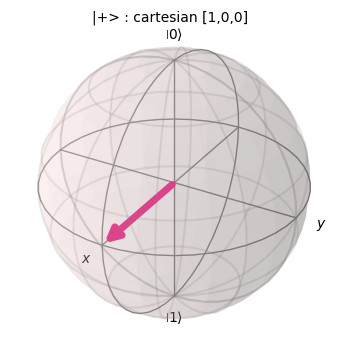

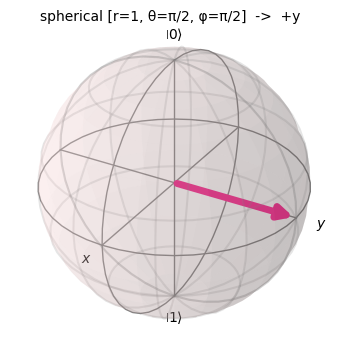

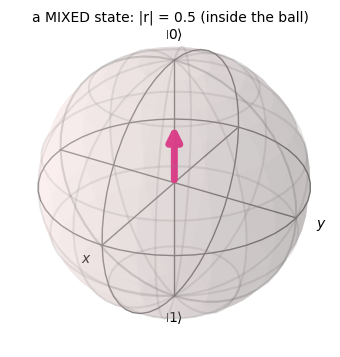

In [3]:
show(plot_bloch_vector([1, 0, 0], title="|+> : cartesian [1,0,0]", figsize=(3.2, 3.2)))
show(plot_bloch_vector([1, np.pi / 2, np.pi / 2], coord_type="spherical", title="spherical [r=1, θ=π/2, φ=π/2]  ->  +y", figsize=(3.2, 3.2)))
show(plot_bloch_vector([0, 0, 0.5], title="a MIXED state: |r| = 0.5 (inside the ball)", figsize=(3.2, 3.2)))

### 2.2 Gates as rotations of the vector
Every single-qubit gate is a **rotation of the Bloch sphere** (up to global phase). Track the vector through a gate sequence:

In [4]:
def walk(gates):
    qc = QuantumCircuit(1)
    print(f"{'after':<10} {'x':>6} {'y':>6} {'z':>6}")
    print(f"{'start':<10} {0:>6.2f} {0:>6.2f} {1:>6.2f}")
    for name, apply in gates:
        apply(qc)
        r = bloch_vector(Statevector(qc))
        print(f"{name:<10} {r[0]:>6.2f} {r[1]:>6.2f} {r[2]:>6.2f}")

walk([("H",  lambda q: q.h(0)),          # z-axis -> x-axis
      ("S",  lambda q: q.s(0)),          # rotate 90° about z : x -> y
      ("H",  lambda q: q.h(0)),          # swaps x<->z (and flips y) : y -> -y
      ("X",  lambda q: q.x(0)),          # 180° about x : z -> -z, y -> -y
      ("RY(π/2)", lambda q: q.ry(np.pi / 2, 0))])

after           x      y      z
start        0.00   0.00   1.00
H            1.00   0.00   0.00
S            0.00   1.00   0.00
H            0.00  -1.00   0.00
X            0.00   1.00   0.00
RY(π/2)      0.00   1.00   0.00


| Gate | Rotation of the Bloch sphere |
|---|---|
| `X`, `Y`, `Z` | $\pi$ about the x, y, z axis |
| `H` | $\pi$ about the axis $(x+z)/\sqrt2$ — swaps x ↔ z, flips y |
| `S`, `T` | $\pi/2$, $\pi/4$ about z |
| `RX(θ)`, `RY(θ)`, `RZ(θ)` | $\theta$ about x, y, z |
| `P(λ)` | $\lambda$ about z (same as `RZ(λ)` up to global phase) |

**Global phase is invisible**: multiplying a state by $e^{i\gamma}$ changes *nothing* on the Bloch sphere.

In [5]:
qc = QuantumCircuit(1); qc.ry(0.9, 0)
a = Statevector(qc)
b = Statevector(np.exp(1j * 1.234) * a.data)          # same physical state, different global phase
print("amplitudes differ :", np.allclose(a.data, b.data) is False)
print("Bloch vectors equal:", np.allclose(bloch_vector(a), bloch_vector(b)))

amplitudes differ : True
Bloch vectors equal: True


---
## 3 · `plot_bloch_multivector`

```python
plot_bloch_multivector(state, title='', figsize=None, *, reverse_bits=False,
                       filename=None, font_size=None, title_font_size=None, title_pad=1)
```

| Parameter | Meaning |
|---|---|
| `state` | `Statevector`, `DensityMatrix`, or array |
| `title`, `title_font_size`, `title_pad` | overall title |
| `figsize`, `font_size` | size / label font |
| `reverse_bits` | order the spheres **from the highest qubit** to qubit 0 |
| `filename` | save to file (function then returns `None`) |

**Layout:** one sphere per qubit, titled `qubit 0, qubit 1, …`, drawn **left → right in increasing qubit index** (reverse with `reverse_bits=True`).

### 3.1 What exactly is drawn? — the *reduced* state
For qubit $k$ the sphere shows the Bloch vector of the **reduced density matrix** $\rho_k=\operatorname{Tr}_{\text{others}}|\psi\rangle\langle\psi|$ — i.e. everything you can learn from qubit $k$ **alone**. Our `bloch_vector(state, k)` computes exactly $(\operatorname{Tr}\rho_kX,\operatorname{Tr}\rho_kY,\operatorname{Tr}\rho_kZ)$.

### 3.2 A product state — every arrow touches the surface

qubit 0: r = [1. 0. 0.]   |r| = 1.000
qubit 1: r = [0. 1. 0.]   |r| = 1.000
qubit 2: r = [ 0.  0. -1.]   |r| = 1.000


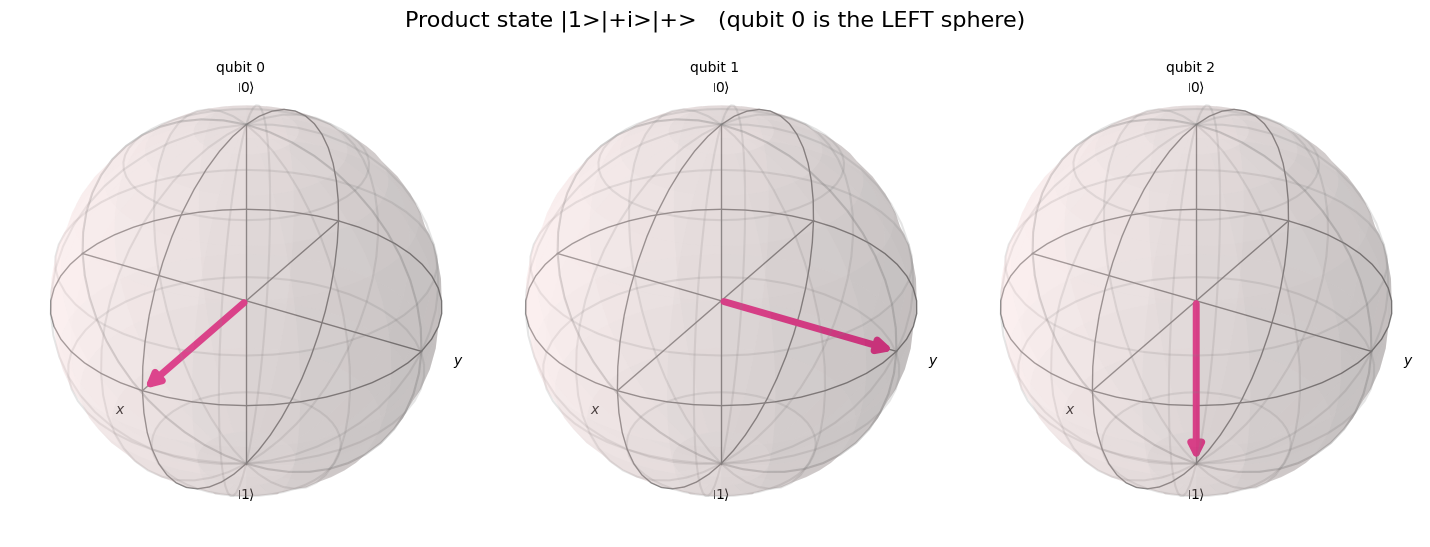

In [6]:
prod = QuantumCircuit(3)
prod.h(0)                  # qubit 0 -> |+>   (+x)
prod.h(1); prod.s(1)       # qubit 1 -> |+i>  (+y)
prod.x(2)                  # qubit 2 -> |1>   (-z)
for k in range(3):
    print(f"qubit {k}: r = {bloch_vector(Statevector(prod), k).round(3)}   |r| = {np.linalg.norm(bloch_vector(Statevector(prod), k)):.3f}")
show(plot_bloch_multivector(Statevector(prod), title="Product state |1>|+i>|+>   (qubit 0 is the LEFT sphere)"))

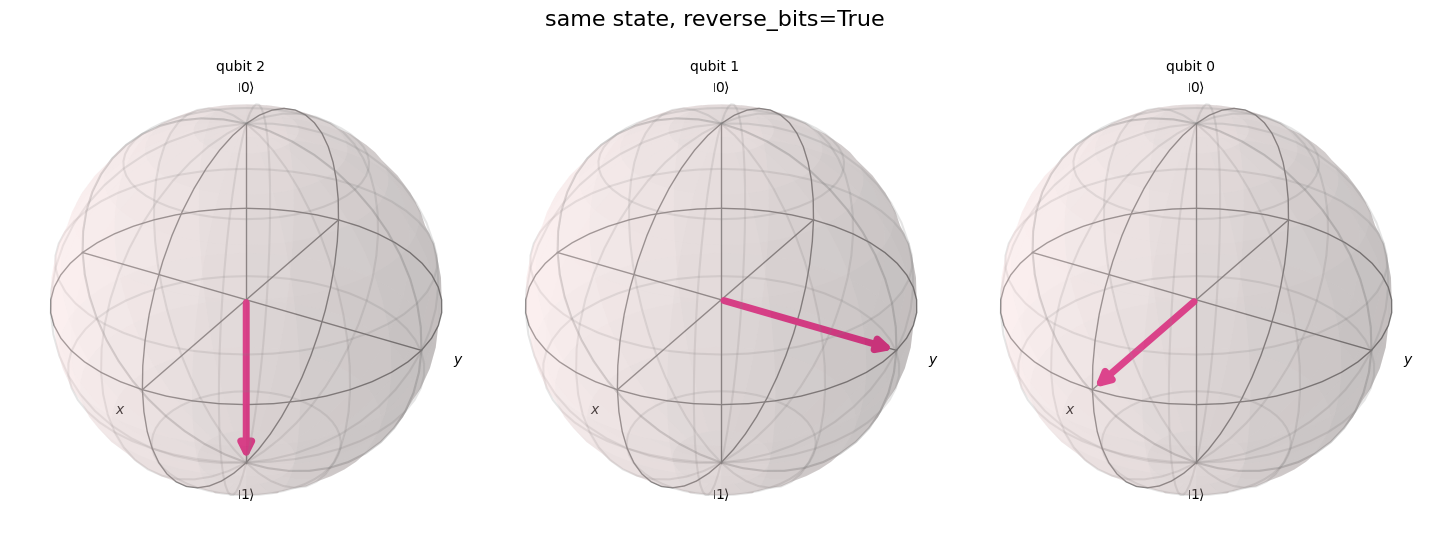

In [7]:
show(plot_bloch_multivector(Statevector(prod), reverse_bits=True, title="same state, reverse_bits=True"))

### 3.3 An entangled state — the arrows vanish
For a Bell state each qubit *alone* is maximally mixed: $\rho_k=I/2$, so $\vec r_k=\vec 0$. **Zero-length arrow = the qubit is entangled with the rest.**

qubit 0: r = [0. 0. 0.], reduced state = [[(0.5+0j), 0j], [0j, (0.5+0j)]]
qubit 1: r = [0. 0. 0.], reduced state = [[(0.5+0j), 0j], [0j, (0.5+0j)]]


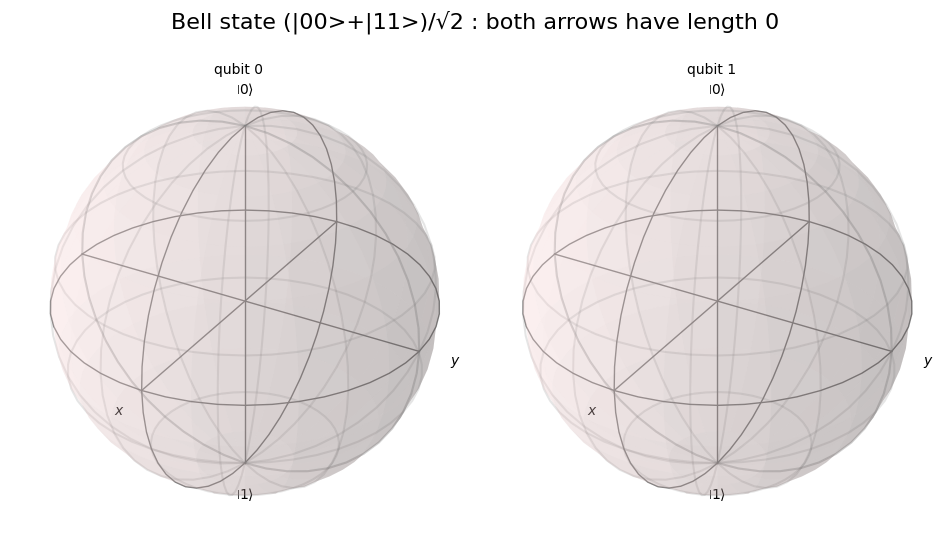

In [8]:
bell = QuantumCircuit(2); bell.h(0); bell.cx(0, 1)
sv = Statevector(bell)
for k in range(2):
    print(f"qubit {k}: r = {bloch_vector(sv, k).round(3)}, reduced state =", partial_trace(sv, [1 - k]).data.round(3).tolist())
show(plot_bloch_multivector(sv, title="Bell state (|00>+|11>)/√2 : both arrows have length 0"))

### 3.4 Partial entanglement — length measures *how much*
For $|\psi\rangle=\cos\frac\theta2|00\rangle+\sin\frac\theta2|11\rangle$ (built by `RY(θ)` then `CX`):

$$\rho_0=\mathrm{diag}\bigl(\cos^2\tfrac\theta2,\ \sin^2\tfrac\theta2\bigr)\ \Rightarrow\ \vec r=(0,0,\cos\theta),\qquad |\vec r|=|\cos\theta| .$$

$\theta=0$ → product state (length 1); $\theta=\pi/2$ → Bell state (length 0).

     θ |  |r| from state |  |cos θ|
 0.000 |          1.0000 |   1.0000
 0.524 |          0.8660 |   0.8660
 0.785 |          0.7071 |   0.7071
 1.047 |          0.5000 |   0.5000
 1.571 |          0.0000 |   0.0000


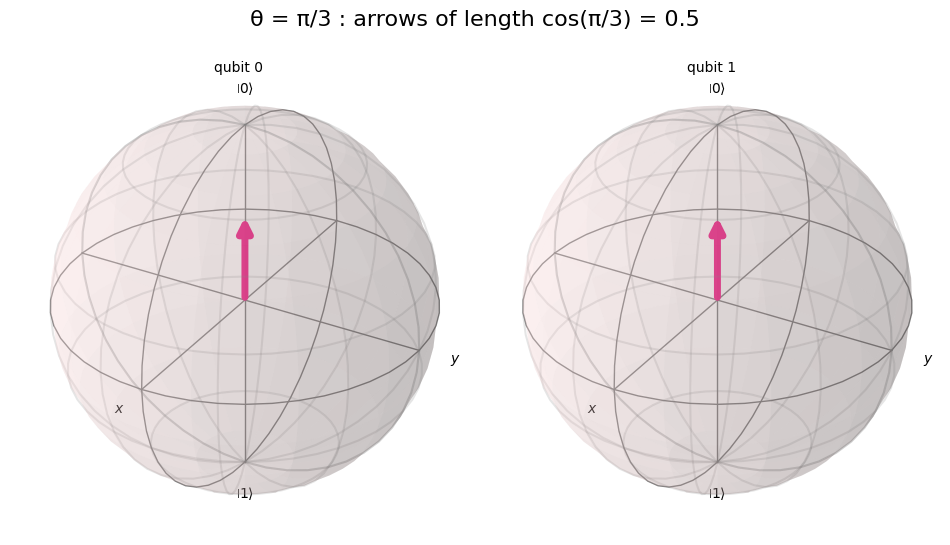

In [9]:
print(f"{'θ':>6} | {'|r| from state':>15} | {'|cos θ|':>8}")
for theta in [0, np.pi / 6, np.pi / 4, np.pi / 3, np.pi / 2]:
    qc = QuantumCircuit(2); qc.ry(theta, 0); qc.cx(0, 1)
    length = np.linalg.norm(bloch_vector(Statevector(qc), 0))
    print(f"{theta:6.3f} | {length:>15.4f} | {abs(np.cos(theta)):>8.4f}")

qc = QuantumCircuit(2); qc.ry(np.pi / 3, 0); qc.cx(0, 1)
show(plot_bloch_multivector(Statevector(qc), title="θ = π/3 : arrows of length cos(π/3) = 0.5"))

### 3.5 Larger states: GHZ, and mixing entangled + unentangled qubits

GHZ                    |r_k| = [0.0, 0.0, 0.0]
Bell(0,1) ⊗ |+>(2)     |r_k| = [0.0, 0.0, 1.0]


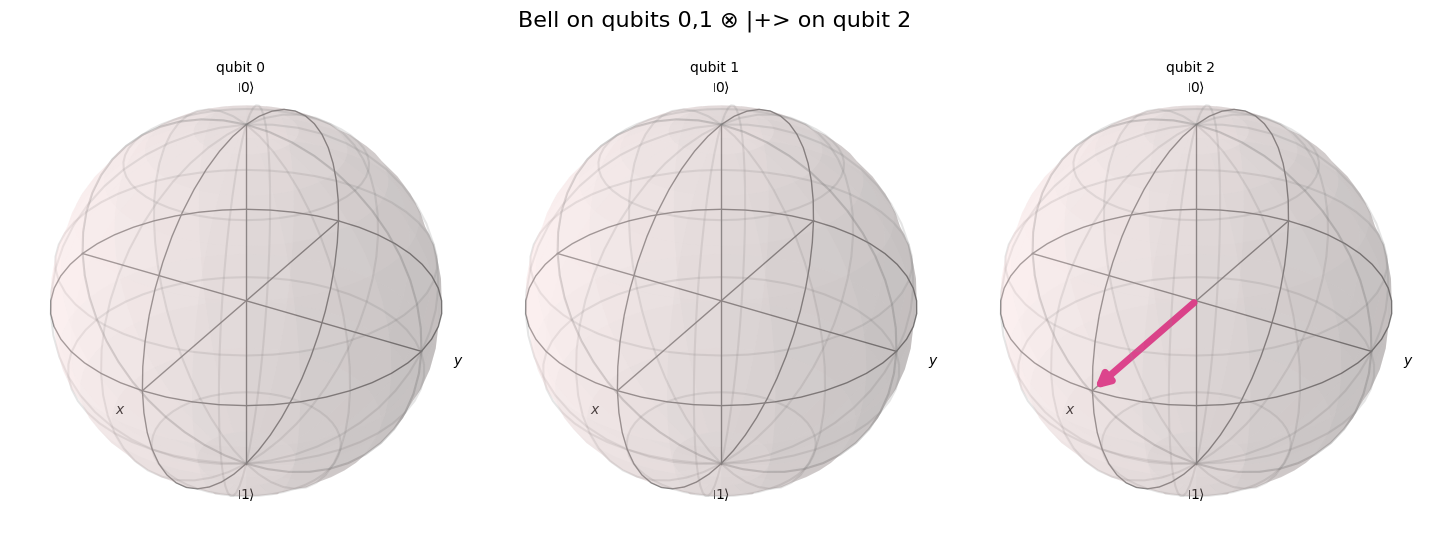

In [10]:
ghz = QuantumCircuit(3); ghz.h(0); ghz.cx(0, 1); ghz.cx(1, 2)
mixed = QuantumCircuit(3); mixed.h(0); mixed.cx(0, 1); mixed.h(2)          # qubits 0,1 entangled; qubit 2 separate (|+>)
for name, c in [("GHZ", ghz), ("Bell(0,1) ⊗ |+>(2)", mixed)]:
    lengths = [round(float(np.linalg.norm(bloch_vector(Statevector(c), k))), 3) for k in range(3)]
    print(f"{name:<22} |r_k| = {lengths}")
show(plot_bloch_multivector(Statevector(mixed), title="Bell on qubits 0,1 ⊗ |+> on qubit 2"))

> **Rule (pure global states):** qubit $k$ is **unentangled** with the rest ⇔ $|\vec r_k|=1$. The state is a product state of single qubits ⇔ **all** arrows have length 1.
>
> **Limitations:** the spheres throw away the *correlations*. Bell $|\Phi^+\rangle$, Bell $|\Psi^-\rangle$ and GHZ all show **only zero arrows** — Bloch spheres cannot tell different entangled states apart. Use the **Q-sphere** (§4) or the Pauli vector (§5) for that.

In [11]:
# Different entangled states, identical Bloch pictures:
def bell_variant(kind):
    qc = QuantumCircuit(2); qc.h(0); qc.cx(0, 1)
    if kind == "Phi-": qc.z(0)
    if kind == "Psi+": qc.x(1)
    if kind == "Psi-": qc.x(1); qc.z(0)
    return qc
for kind in ["Phi+", "Phi-", "Psi+", "Psi-"]:
    s = Statevector(bell_variant(kind))
    print(f"{kind}: |r_0|, |r_1| =", [round(float(np.linalg.norm(bloch_vector(s, k))), 3) for k in range(2)],
          "| amplitudes =", s.data.round(3))

Phi+: |r_0|, |r_1| = [0.0, 0.0] | amplitudes = [0.707+0.j 0.   +0.j 0.   +0.j 0.707+0.j]
Phi-: |r_0|, |r_1| = [0.0, 0.0] | amplitudes = [ 0.707+0.j -0.   +0.j  0.   +0.j -0.707+0.j]
Psi+: |r_0|, |r_1| = [0.0, 0.0] | amplitudes = [0.   +0.j 0.707+0.j 0.707+0.j 0.   +0.j]
Psi-: |r_0|, |r_1| = [0.0, 0.0] | amplitudes = [ 0.   +0.j -0.707+0.j  0.707+0.j -0.   +0.j]


### 3.6 Mixed states and other input types
`plot_bloch_multivector` also takes a `DensityMatrix` (mixed states give vectors **shorter than 1**), or a raw array of amplitudes.

Bloch vector of the noisy state: [0.5 0.  0. ] | purity: 0.625


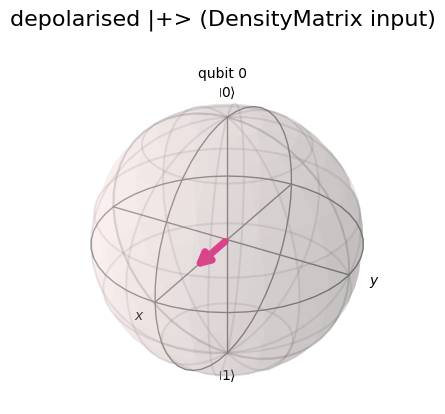

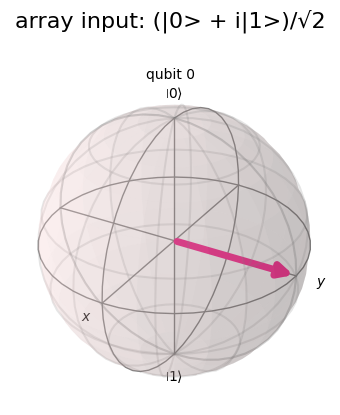

In [12]:
# A pure |+> that has been 50% depolarised: rho = 0.5*|+><+| + 0.5*I/2   ->  |r| = 0.5
plus = DensityMatrix(Statevector.from_label("+"))
noisy = 0.5 * plus + 0.5 * DensityMatrix(np.eye(2) / 2)
print("Bloch vector of the noisy state:", bloch_vector(noisy).round(3), "| purity:", noisy.purity().real.round(3))
show(plot_bloch_multivector(noisy, title="depolarised |+> (DensityMatrix input)", figsize=(3.5, 3.5)))

# raw array also works
show(plot_bloch_multivector(np.array([1, 1j]) / np.sqrt(2), title="array input: (|0> + i|1>)/√2", figsize=(3.5, 3.5)))

---
## 4 · `plot_state_qsphere`

```python
plot_state_qsphere(state, figsize=None, ax=None, show_state_labels=True,
                   show_state_phases=False, use_degrees=False, *, filename=None)
```

The **Q-sphere** draws the *whole* $n$-qubit state in one picture. Each of the $2^n$ basis states is a **node** on a sphere:

| Visual property | Encodes |
|---|---|
| **Latitude** | the **Hamming weight** (number of 1s). North pole = $|0\ldots0\rangle$, south pole = $|1\ldots1\rangle$; states with the same weight sit on the same circle of latitude |
| **Node size** (and the line from the centre) | the **magnitude** of the amplitude — bigger node ⇔ larger $|a_i|$ (so probability $|a_i|^2$) |
| **Node colour** | the **phase** of the amplitude, read on the colour wheel drawn beside the sphere (0, π/2, π, 3π/2) |
| `show_state_labels` | print $|x\rangle$ next to each non-zero node |
| `show_state_phases` | also print the numeric phase; `use_degrees=True` prints degrees instead of radians |

### 4.1 Global phase is removed
The plot divides the state by the phase of its **largest-magnitude amplitude**, so *that* node always has phase 0 and every other phase is **relative to it**. (This is why a global phase factor never changes the picture.)

amplitudes           : [ 0.5+0.j   0. +0.5j -0.5+0.j   0. -0.5j]
relative phases (deg): {'00': 0.0, '01': 90.0, '10': 180.0, '11': 270.0}


labels printed by the plot: ['$\\vert00\\rangle$ $0.0^\\circ$', '$\\vert01\\rangle$ $90.0^\\circ$', '$\\vert10\\rangle$ $180.0^\\circ$', '$\\vert11\\rangle$ $270.0^\\circ$']


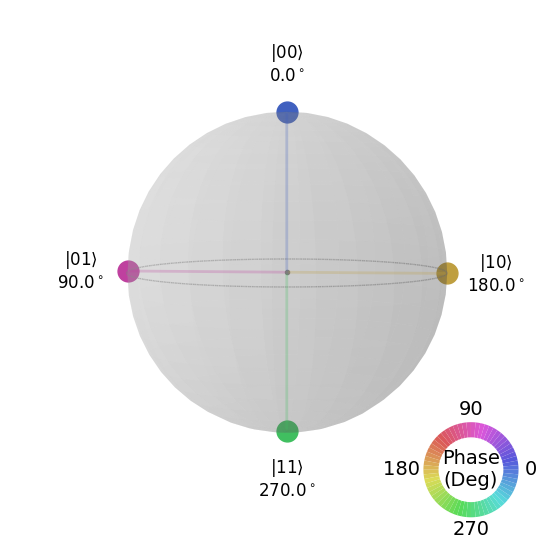

In [13]:
def relative_phases_deg(state):
    # phase of each amplitude relative to the largest one (first one on ties) — what the Q-sphere prints
    amp = Statevector(state).data
    ref = int(np.round(np.abs(amp), 13).argmax())
    nq = int(np.log2(len(amp)))
    out = {}
    for i, a in enumerate(amp):
        if abs(a) > 1e-9:
            out[format(i, f"0{nq}b")] = round(float((np.degrees(np.angle(a) - np.angle(amp[ref])) + 360) % 360), 1)
    return out

def qsphere_texts(fig):
    return [t.get_text().replace("\n", " ") for ax in fig.axes for t in ax.texts if "vert" in t.get_text()]

# a state with 4 equal-magnitude amplitudes and four different phases
qc = QuantumCircuit(2); qc.h([0, 1]); qc.s(0); qc.z(1)
st = Statevector(qc)
print("amplitudes           :", st.data.round(3))
print("relative phases (deg):", relative_phases_deg(st))

fig = plot_state_qsphere(st, show_state_phases=True, use_degrees=True)
print("labels printed by the plot:", qsphere_texts(fig))
show(fig)

In [14]:
# Global phase has no effect: multiply the state by e^{i*0.77} and compare the printed phases
st2 = Statevector(np.exp(0.77j) * st.data)
print("same relative phases after a global phase:", relative_phases_deg(st2) == relative_phases_deg(st))

same relative phases after a global phase: True


### 4.2 A gallery of states — what to expect

 |+>|+>: nodes -> relative phases {'00': 0.0, '01': 0.0, '10': 0.0, '11': 0.0}


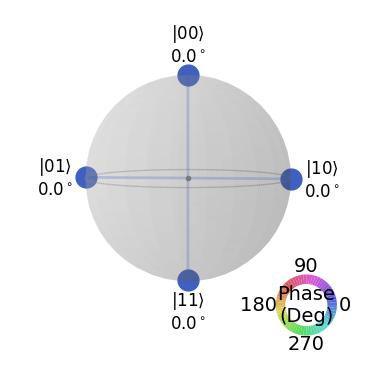

   Phi+: nodes -> relative phases {'00': 0.0, '11': 0.0}


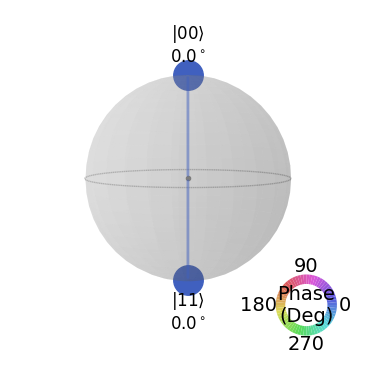

   Phi-: nodes -> relative phases {'00': 0.0, '11': 180.0}


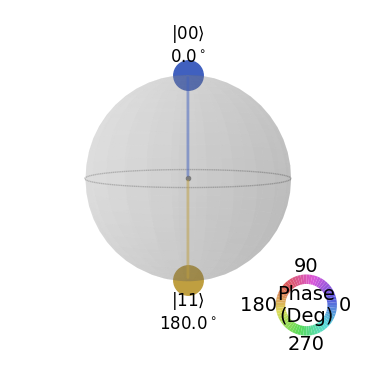

   Psi+: nodes -> relative phases {'01': 0.0, '10': 0.0}


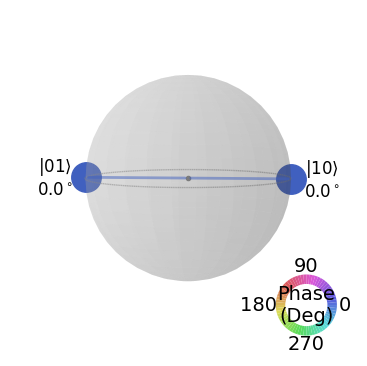

    GHZ: nodes -> relative phases {'000': 0.0, '111': 0.0}


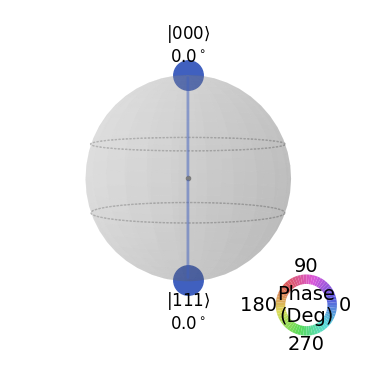

      W: nodes -> relative phases {'001': 0.0, '010': 0.0, '100': 0.0}


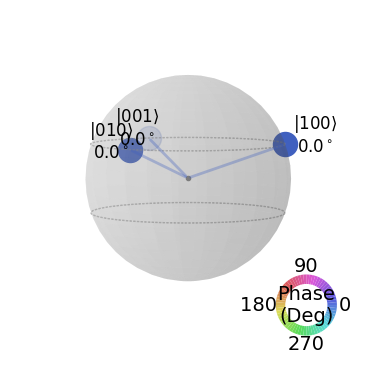

In [15]:
def build(kind):
    qc = QuantumCircuit(3 if kind in ("GHZ", "W") else 2)
    if kind == "|+>|+>":   qc.h([0, 1])
    if kind == "Phi+":     qc.h(0); qc.cx(0, 1)
    if kind == "Phi-":     qc.h(0); qc.cx(0, 1); qc.z(0)
    if kind == "Psi+":     qc.h(0); qc.cx(0, 1); qc.x(1)
    if kind == "GHZ":      qc.h(0); qc.cx(0, 1); qc.cx(1, 2)
    if kind == "W":
        qc.ry(2 * np.arcsin(1 / np.sqrt(3)), 2)
        qc.ch(2, 1, ctrl_state=0)
        qc.append(XGate().control(2, ctrl_state="00"), [1, 2, 0])
    return qc

for kind in ["|+>|+>", "Phi+", "Phi-", "Psi+", "GHZ", "W"]:
    s = Statevector(build(kind))
    print(f"{kind:>7}: nodes -> relative phases {relative_phases_deg(s)}")
    show(plot_state_qsphere(s, show_state_phases=True, use_degrees=True, figsize=(4.5, 4.5)))

Things to notice:

- `|+>|+>`: **four equal nodes** (one per weight pattern 00 / 01 / 10 / 11) — a product state looks "spread out".
- `Phi+` vs `Phi-`: **same nodes**, but `|11>` is **180° out of phase** (different colour). Bloch spheres could not show this.
- `Phi+` (`00`,`11`) vs `Psi+` (`01`,`10`): different **latitudes** — poles vs equator.
- **GHZ**: only the **north and south poles** are occupied (`000`, `111`).
- **W state**: three equal nodes on the **weight-1 circle** (`001`, `010`, `100`).

### 4.3 Mixed states
For a `DensityMatrix` the sphere is drawn **for every eigenvector of $\rho$ with eigenvalue above a small threshold** (about 0.001), overlaid on the same sphere; eigenvalue *weights* are not encoded. For genuinely mixed states prefer `plot_state_city` / `plot_state_hinton` / `plot_state_paulivec` (§5).

eigenvalues of rho: [0.  0.  0.5 0.5]


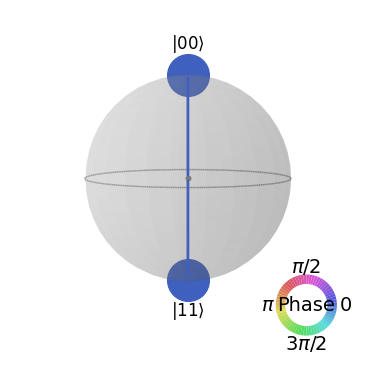

In [16]:
mixed_rho = DensityMatrix(np.diag([0.5, 0, 0, 0.5]))        # 50/50 classical mixture of |00> and |11>
print("eigenvalues of rho:", np.linalg.eigvalsh(mixed_rho.data).round(3))
show(plot_state_qsphere(mixed_rho, figsize=(4.5, 4.5)))

---
## 5 · The sibling plots

### 5.1 `plot_state_paulivec` — Pauli expectation values (Task 1.1 in picture form)
One bar per Pauli string $P$, height $\operatorname{Tr}(\rho P)$ ∈ [−1, 1]. Only strings with non-zero value are drawn. For $|\Phi^+\rangle$ you get exactly the stabiliser story from Task 1.1: $II=+1,\ XX=+1,\ ZZ=+1,\ YY=-1$.

bars drawn      : {'II': 1.0, 'XX': 1.0, 'YY': -1.0, 'ZZ': 1.0}
<P> computed    : {'II': 1.0, 'XX': 1.0, 'YY': -1.0, 'ZZ': 1.0}
identical: True


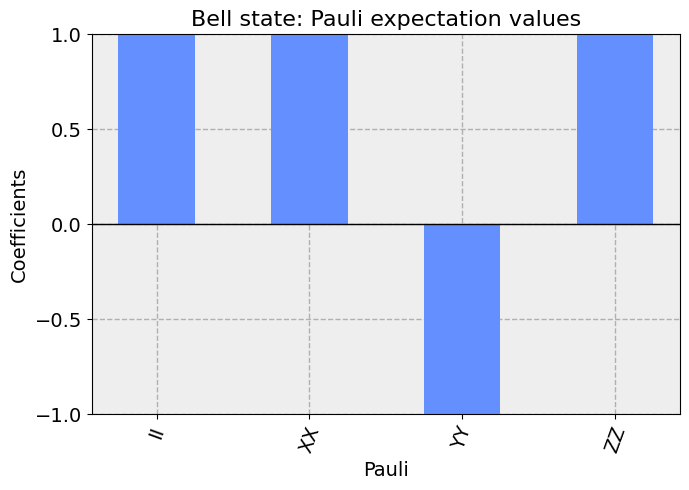

In [17]:
fig = plot_state_paulivec(Statevector(bell), title="Bell state: Pauli expectation values")
ax = fig.axes[0]
shown = dict(zip([t.get_text() for t in ax.get_xticklabels()], [round(float(p.get_height()), 3) for p in ax.patches]))
print("bars drawn      :", shown)
computed = {l: round(float(Statevector(bell).expectation_value(Pauli(l)).real), 3) for l in shown}
print("<P> computed    :", computed)
print("identical:", shown == computed)
show(fig)

### 5.2 `plot_state_city` and `plot_state_hinton` — the density matrix itself
Both draw the **real** and **imaginary** parts of $\rho$ as two panels. *City*: 3-D bars; *Hinton*: squares with area ∝ magnitude (white positive, black negative). Off-diagonal elements are **coherences** — they distinguish a superposition from a classical mixture.

rho(|+>)      =
 [[0.5+0.j 0.5+0.j]
 [0.5+0.j 0.5+0.j]]
rho(mixture)  =
 [[0.5+0.j 0. +0.j]
 [0. +0.j 0.5+0.j]]


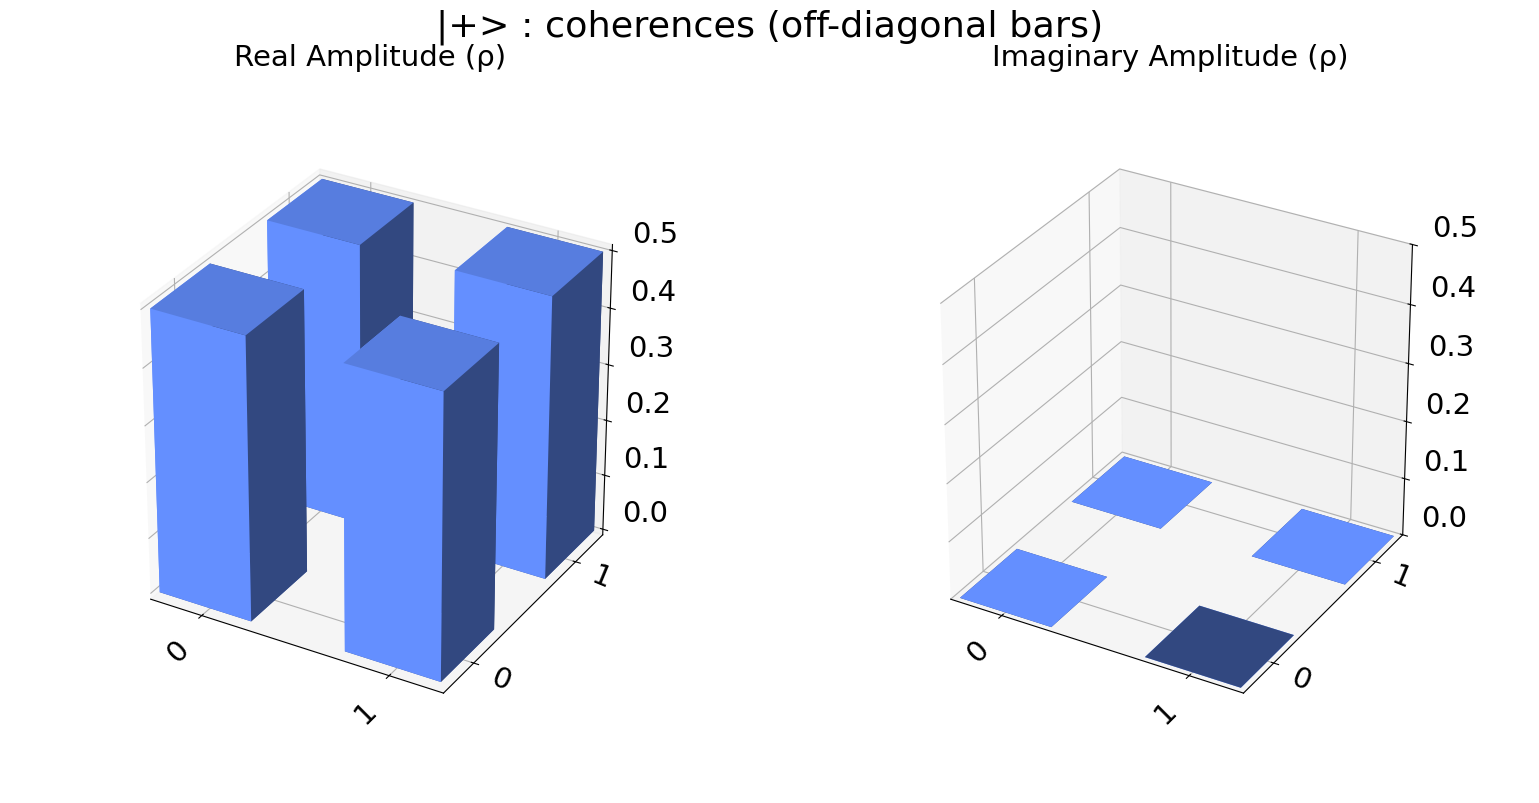

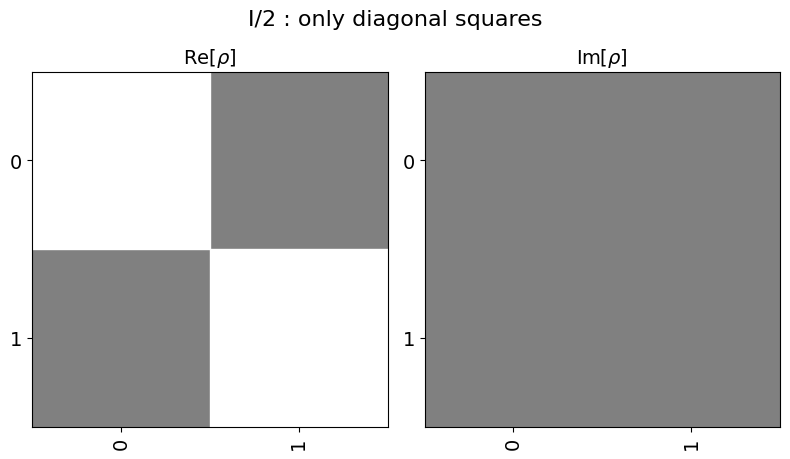

In [18]:
pure = DensityMatrix(Statevector.from_label("+"))                    # superposition: coherences present
classical = DensityMatrix(np.eye(2) / 2)                              # classical 50/50 mixture: diagonal only
print("rho(|+>)      =\n", pure.data.round(2))
print("rho(mixture)  =\n", classical.data.round(2))
show(plot_state_city(pure, title="|+> : coherences (off-diagonal bars)"))
show(plot_state_hinton(classical, title="I/2 : only diagonal squares"))

---
## 6 · Choosing the right plot

| I want to… | Use |
|---|---|
| see where **one** qubit points | `plot_bloch_vector` / `plot_bloch_multivector` |
| check if a pure state is a **product state** / find entangled qubits | `plot_bloch_multivector` (all arrows length 1?) |
| see the **amplitudes and relative phases** of a few-qubit pure state | `plot_state_qsphere` |
| distinguish **different entangled states** (Φ⁺ vs Φ⁻ vs GHZ) | `plot_state_qsphere` or `plot_state_paulivec` |
| inspect a **mixed** state / coherences | `plot_state_city`, `plot_state_hinton`, or `paulivec` |
| see **measurement statistics** | `plot_histogram` (Task 2.2) — states are *not* measurement results |

Scale: $2^n$ nodes make the Q-sphere crowded beyond ~5 qubits, and the density-matrix plots grow as $4^n$; state plots are for **small** systems, always **simulator-only** (real hardware cannot hand you amplitudes).

---
## 7 · Gotchas checklist

1. **Each Bloch sphere is the *reduced* state of one qubit,** not a "piece" of the global state. A **zero-length arrow means entangled** (for a pure global state).
2. **Bloch spheres cannot distinguish entangled states** — Φ⁺, Φ⁻, Ψ± and GHZ all show only centre points. Use the Q-sphere / paulivec.
3. **Global phase is invisible** in both plots; the Q-sphere phases are **relative to the largest amplitude**.
4. **Sphere order:** `qubit 0` is the **left-most** sphere; `reverse_bits=True` puts the highest qubit first. (Bit-strings in labels follow the little-endian convention: qubit 0 is the rightmost character of $|x\rangle$.)
5. **Q-sphere geometry:** north pole $|0\ldots0\rangle$, south pole $|1\ldots1\rangle$; latitude = Hamming weight; size ∝ magnitude, colour = phase.
6. **Mixed states:** Bloch vectors are shorter than 1; the Q-sphere decomposes into eigenvectors and ignores their weights.
7. **Inputs:** `Statevector`, `DensityMatrix` or an array. A *circuit* must first be converted (`Statevector(qc)`), and it must contain **no measurements**.
8. **`filename=` makes the function return `None`** (the figure goes to disk).
9. **State plots are exact-simulation tools;** on hardware you reconstruct states by tomography, not by reading amplitudes.
10. **`plot_bloch_vector` takes `[x, y, z]`** by default; spherical coordinates need `coord_type="spherical"` and mean `[r, θ, φ]`.

---
## 8 · Exercises

### Exercise 1 — a Bloch vector from a circuit
`prep` applies `RY(π/3)` then `RZ(π/2)` to $|0\rangle$. Return its Bloch vector `(x, y, z)` as three floats. (Think rotations first: where does $RY(\pi/3)$ send the north pole? Then rotate about z by $\pi/2$.)

In [19]:
prep1 = QuantumCircuit(1)
prep1.ry(np.pi / 3, 0)
prep1.rz(np.pi / 2, 0)

def exercise_1():
    # TODO: return (x, y, z)
    return None

ans1 = exercise_1()

In [20]:
def check_1(t):
    if t is None: return _todo("Exercise 1")
    rho = DensityMatrix(prep1).data
    X, Y, Z = Pauli("X").to_matrix(), Pauli("Y").to_matrix(), Pauli("Z").to_matrix()
    truth = [float(np.real(np.trace(rho @ P))) for P in (X, Y, Z)]
    assert np.allclose(t, truth, atol=1e-8), f"expected {np.round(truth, 3)}, got {t}"
    print("✅ Exercise 1 passed —", tuple(round(v, 3) for v in t), "(RY tilts the vector into the x–z plane; RZ then swings it about z.)")
check_1(ans1)

⏳ Exercise 1: not attempted yet — fill in the TODO above and re-run this cell.


### Exercise 2 — how entangled?
For $\theta=1.0$ rad, let $|\psi\rangle=\cos\frac\theta2|00\rangle+\sin\frac\theta2|11\rangle$ (an `RY(θ)` on qubit 0 followed by `CX(0,1)`). Return the **length of the Bloch vector of qubit 0** as a float.

In [21]:
def exercise_2():
    # TODO: length |r| of qubit 0's Bloch vector for theta = 1.0
    return None

ans2 = exercise_2()

In [22]:
def check_2(v):
    if v is None: return _todo("Exercise 2")
    assert abs(v - abs(np.cos(1.0))) < 1e-8, f"expected |cos(1.0)| = {abs(np.cos(1.0)):.4f}, got {v}"
    print(f"✅ Exercise 2 passed — |r| = {v:.4f} = |cos θ|: partially entangled (1 would be a product state, 0 a Bell state).")
check_2(ans2)

⏳ Exercise 2: not attempted yet — fill in the TODO above and re-run this cell.


### Exercise 3 — who is entangled?
Four 2-qubit circuits are defined below. Using **only the lengths of the Bloch vectors**, return the list of indices of the circuits whose qubits are **entangled**.

In [23]:
cands = []
c = QuantumCircuit(2); c.h(0); c.h(1);                              cands.append(c)   # 0
c = QuantumCircuit(2); c.h(0); c.cx(0, 1);                          cands.append(c)   # 1
c = QuantumCircuit(2); c.ry(0.8, 0); c.cx(0, 1); c.x(1);            cands.append(c)   # 2
c = QuantumCircuit(2); c.h(0); c.cx(0, 1); c.cx(0, 1); c.h(0);      cands.append(c)   # 3

def exercise_3():
    # TODO: return a list of indices into `cands` that are entangled
    return None

ans3 = exercise_3()

In [24]:
def check_3(lst):
    if lst is None: return _todo("Exercise 3")
    truth = [i for i, c in enumerate(cands) if partial_trace(Statevector(c), [1]).purity().real < 1 - 1e-9]   # independent test: purity
    assert sorted(lst) == truth, f"expected {truth}, got {sorted(lst)}"
    print("✅ Exercise 3 passed — entangled circuits:", sorted(lst), "(circuit 3 undoes its own CX, so it ends as a product state).")
check_3(ans3)

⏳ Exercise 3: not attempted yet — fill in the TODO above and re-run this cell.


### Exercise 4 — read the Q-sphere phases
For the 2-qubit state built below, return a **dict** `{bit-string: phase in degrees}` listing the phase that `plot_state_qsphere(..., show_state_phases=True, use_degrees=True)` would print for each non-zero node (remember: relative to the largest amplitude; on ties the first basis state is the reference). Work it out by hand first — which amplitude gets $i$ from `S`, which gets $-1$ from `Z`?

In [25]:
prep4 = QuantumCircuit(2)
prep4.h([0, 1])
prep4.s(0)          # multiplies amplitudes with qubit0 = 1 by i
prep4.z(1)          # multiplies amplitudes with qubit1 = 1 by -1

def exercise_4():
    # TODO: return {'00': ..., '01': ..., '10': ..., '11': ...} in degrees
    return None

ans4 = exercise_4()

In [26]:
def check_4(d):
    if d is None: return _todo("Exercise 4")
    truth = relative_phases_deg(Statevector(prep4))
    assert {k: round(float(v) % 360, 1) for k, v in d.items()} == truth, f"expected {truth}, got {d}"
    # confirm against the real figure
    fig = plot_state_qsphere(Statevector(prep4), show_state_phases=True, use_degrees=True)
    printed = qsphere_texts(fig); plt.close(fig)
    print("✅ Exercise 4 passed — the plot prints:", printed)
check_4(ans4)

⏳ Exercise 4: not attempted yet — fill in the TODO above and re-run this cell.


### Exercise 5 — design a picture
Return a **3-qubit circuit** whose `plot_bloch_multivector` shows: qubit 0 as a vector of length 1 pointing along **+x**, and qubits 1 and 2 both as **zero-length** arrows (centre of the sphere).

In [27]:
def exercise_5():
    # TODO: build the 3-qubit circuit
    return None

ans5 = exercise_5()

In [28]:
def check_5(qc):
    if qc is None: return _todo("Exercise 5")
    assert qc.num_qubits == 3 and "measure" not in qc.count_ops(), "need 3 qubits and no measurements"
    s = Statevector(qc)
    r0, r1, r2 = (bloch_vector(s, k) for k in range(3))
    assert np.allclose(r0, [1, 0, 0], atol=1e-8), f"qubit 0 should point along +x, got {r0.round(3)}"
    assert np.linalg.norm(r1) < 1e-8 and np.linalg.norm(r2) < 1e-8, "qubits 1 and 2 must have zero-length arrows"
    print("✅ Exercise 5 passed — one separable qubit, two entangled ones.")
    show(plot_bloch_multivector(s, title="Exercise 5"))
check_5(ans5)

⏳ Exercise 5: not attempted yet — fill in the TODO above and re-run this cell.


### Exercise 6 (challenge) — build the W state
Build a 3-qubit circuit for the **W state** $\frac{|001\rangle+|010\rangle+|100\rangle}{\sqrt3}$. Any method is accepted (`prepare_state` is allowed), but try with gates: an `RY` to get the right amplitude, a controlled-`H`, and an *open-controlled* `X` (Task 1.2's `ctrl_state`).

In [29]:
def exercise_6():
    # TODO: return a 3-qubit circuit preparing the W state (no measurements)
    return None

ans6 = exercise_6()

In [30]:
def check_6(qc):
    if qc is None: return _todo("Exercise 6")
    W = np.zeros(8, dtype=complex); W[[0b001, 0b010, 0b100]] = 1 / np.sqrt(3)
    assert Statevector(qc).equiv(Statevector(W)), f"not the W state: {Statevector(qc).data.round(3)}"
    print("✅ Exercise 6 passed — W state built.")
    show(plot_state_qsphere(Statevector(qc), figsize=(4.5, 4.5)))
check_6(ans6)

⏳ Exercise 6: not attempted yet — fill in the TODO above and re-run this cell.


### Playground
- Plot `plot_bloch_multivector` for a 4-qubit GHZ state, then for GHZ with one `H` on qubit 0 at the end. Which arrows change?
- Produce the Q-sphere of `QFTGate(3)` applied to `|001>` — what phases appear?
- Build a state with `Statevector.from_label("01+")`, and use `reverse_bits=True`. Which sphere is which?
- Mix two Bell states 50/50 in a `DensityMatrix`; compare `plot_state_qsphere` with `plot_state_city`.

---
## 9 · Exam-style questions

**Q1.** What does each Bloch sphere in `plot_bloch_multivector` show?
- A) one amplitude of the state  B) the reduced state of one qubit  C) the measurement probabilities of a qubit  D) the gate applied to a qubit

<details><summary>Answer</summary>

**B.** The Bloch vector of the reduced density matrix of that qubit.
</details>

**Q2.** A Bloch sphere arrow of **length 0** for qubit $k$ in a pure multi-qubit state means:
- A) the qubit is in $|0\rangle$  B) the qubit is maximally entangled with the rest  C) the qubit was measured  D) the qubit has no gates

<details><summary>Answer</summary>

**B.** Its reduced state is $I/2$.
</details>

**Q3.** In which order are the spheres of `plot_bloch_multivector(state)` drawn by default?
- A) highest qubit first  B) qubit 0 first (left)  C) random  D) by probability

<details><summary>Answer</summary>

**B.** Use `reverse_bits=True` to flip it.
</details>

**Q4.** On the Q-sphere, the **north pole** is the basis state:
- A) $|1\ldots1\rangle$  B) $|0\ldots0\rangle$  C) $|+\ldots+\rangle$  D) the largest amplitude

<details><summary>Answer</summary>

**B.** Latitude is the Hamming weight; $|1\ldots1\rangle$ is the south pole.
</details>

**Q5.** On the Q-sphere, the **colour** of a node encodes:
- A) probability  B) Hamming weight  C) the phase of the amplitude  D) qubit index

<details><summary>Answer</summary>

**C.** Size encodes magnitude; latitude encodes Hamming weight.
</details>

**Q6.** Which states give **identical** `plot_bloch_multivector` pictures?
- A) $|\Phi^+\rangle$ and $|\Phi^-\rangle$  B) $|+\rangle$ and $|-\rangle$  C) $|0\rangle$ and $|1\rangle$  D) $|+\rangle$ and $|+i\rangle$

<details><summary>Answer</summary>

**A.** Both are maximally entangled → zero arrows. (The others point in different directions.)
</details>

**Q7.** Multiplying a state by $e^{i\gamma}$ changes the Bloch plot and Q-sphere phases:
- A) both  B) neither (global phase is invisible)  C) only the Bloch plot  D) only the Q-sphere

<details><summary>Answer</summary>

**B.** The Q-sphere is normalised to the phase of the largest amplitude.
</details>

**Q8.** Which input can you **not** pass directly to `plot_bloch_multivector`?
- A) `Statevector`  B) `DensityMatrix`  C) NumPy array of amplitudes  D) a `QuantumCircuit` with measurements

<details><summary>Answer</summary>

**D.** Convert a measurement-free circuit with `Statevector(qc)` first.
</details>

**Q9.** For `plot_bloch_vector`, `coord_type="spherical"` means the list is:
- A) `[x, y, z]`  B) `[r, θ, φ]`  C) `[θ, φ]`  D) `[φ, θ, r]`

<details><summary>Answer</summary>

**B.**
</details>

**Q10.** `plot_state_paulivec` of $|\Phi^+\rangle$ shows non-zero bars for:
- A) II, XX, YY, ZZ  B) II, XX, ZZ only  C) every Pauli string  D) only ZZ

<details><summary>Answer</summary>

**A.** With values +1, +1, −1, +1.
</details>

---
## 10 · Solutions & explanations

In [31]:
# --- Solution 1 -----------------------------------------------------------
# RY(pi/3)|0> points at polar angle pi/3 in the x-z plane: (sin, 0, cos) = (0.866, 0, 0.5).
# RZ(pi/2) then rotates the x-y components by 90° about z: (x, y) -> (-y, x)  => (0, 0.866, 0.5).
sol1 = tuple(float(v) for v in bloch_vector(Statevector(prep1)))
check_1(sol1)

✅ Exercise 1 passed — (0.0, 0.866, 0.5) (RY tilts the vector into the x–z plane; RZ then swings it about z.)


In [32]:
# --- Solution 2 -----------------------------------------------------------
qc = QuantumCircuit(2); qc.ry(1.0, 0); qc.cx(0, 1)
sol2 = float(np.linalg.norm(bloch_vector(Statevector(qc), 0)))
check_2(sol2)
# rho_0 = diag(cos^2(θ/2), sin^2(θ/2)) -> z = cos^2(θ/2) - sin^2(θ/2) = cos θ

✅ Exercise 2 passed — |r| = 0.5403 = |cos θ|: partially entangled (1 would be a product state, 0 a Bell state).


In [33]:
# --- Solution 3 -----------------------------------------------------------
sol3 = [i for i, c in enumerate(cands) if np.linalg.norm(bloch_vector(Statevector(c), 0)) < 1 - 1e-9]
check_3(sol3)
# 0: H⊗H product.  1: Bell.  2: RY then CX is partially entangled (X on qubit 1 doesn't change that).  3: CX·CX = I, so back to a product state.

✅ Exercise 3 passed — entangled circuits: [1, 2] (circuit 3 undoes its own CX, so it ends as a product state).


In [34]:
# --- Solution 4 -----------------------------------------------------------
# After H⊗H all four amplitudes are 1/2. S multiplies the qubit0=1 terms by i; Z multiplies the qubit1=1 terms by -1:
#   |00>: 1   |01>: i   |10>: -1   |11>: (i)(-1) = -i   ->  0°, 90°, 180°, 270°
sol4 = {"00": 0.0, "01": 90.0, "10": 180.0, "11": 270.0}
check_4(sol4)

✅ Exercise 4 passed — the plot prints: ['$\\vert00\\rangle$ $0.0^\\circ$', '$\\vert01\\rangle$ $90.0^\\circ$', '$\\vert10\\rangle$ $180.0^\\circ$', '$\\vert11\\rangle$ $270.0^\\circ$']


✅ Exercise 5 passed — one separable qubit, two entangled ones.


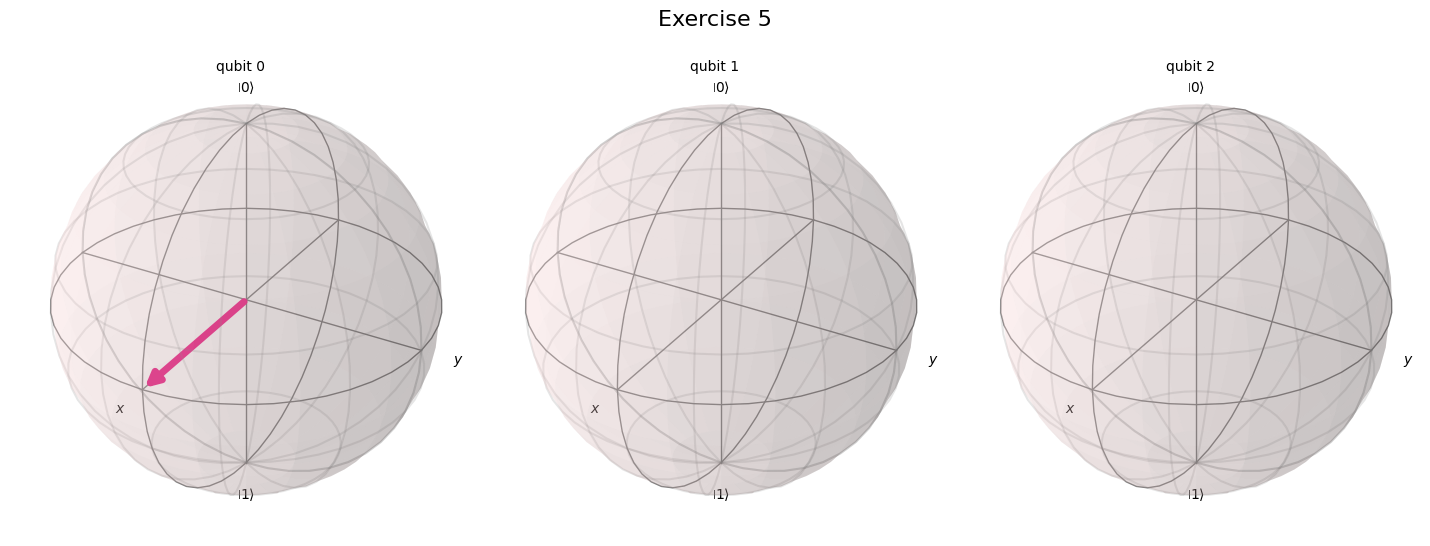

In [35]:
# --- Solution 5 -----------------------------------------------------------
sol5 = QuantumCircuit(3)
sol5.h(0)
sol5.h(1); sol5.cx(1, 2)
check_5(sol5)

✅ Exercise 6 passed — W state built.


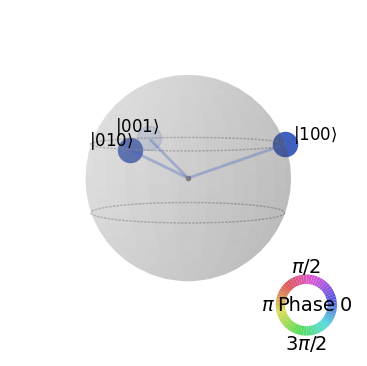

In [36]:
# --- Solution 6 -----------------------------------------------------------
sol6 = QuantumCircuit(3)
sol6.ry(2 * np.arcsin(1 / np.sqrt(3)), 2)                    # sin^2(θ/2) = 1/3  ->  P(q2=1) = 1/3
sol6.ch(2, 1, ctrl_state=0)                                   # q2 = 0 branch (amplitude √(2/3)) is split equally by H on q1
sol6.append(XGate().control(2, ctrl_state="00"), [1, 2, 0])   # only |000> has q1=q2=0 -> becomes |001>
check_6(sol6)

---
## 11 · One-page summary

- **Bloch vector** $\vec r=(\langle X\rangle,\langle Y\rangle,\langle Z\rangle)$; $|\vec r|=1$ pure, $<1$ mixed, $0$ maximally mixed; purity $=(1+|\vec r|^2)/2$. Gates are rotations; global phase is invisible.
- **`plot_bloch_vector`**: `[x,y,z]` or `coord_type="spherical"` → `[r,θ,φ]`.
- **`plot_bloch_multivector(state, title, figsize, *, reverse_bits, filename, font_size, title_font_size, title_pad)`**: one sphere per qubit = **reduced state**; qubit 0 leftmost; **zero arrow ⇒ entangled**; cannot distinguish different entangled states.
- **`plot_state_qsphere(state, figsize, ax, show_state_labels, show_state_phases, use_degrees, *, filename)`**: node per basis state; **latitude = Hamming weight** (N pole $|0…0\rangle$), **size = |amplitude|**, **colour = phase relative to the largest amplitude** (global phase removed); mixed states → eigenvectors overlaid.
- **Siblings:** `plot_state_paulivec` (bars = $\operatorname{Tr}\rho P$), `plot_state_city` / `plot_state_hinton` (real & imaginary parts of $\rho$).
- **Inputs:** `Statevector`, `DensityMatrix`, arrays; circuits need `Statevector(qc)` first (no measurements). Exact simulation only.
- **Section 2 complete.** Next: **Section 3 — Create quantum circuits** (3.1 dynamic circuits, 3.2 parameterized circuits, 3.3 transpile & optimize, 3.4 basic circuits).